#### House Price prediction model 
### BY: `Joshua Igbinedion`

###### **Problem Statement:** The goal is to build a House price prediction model with the given KCC House price dataset using Machine Learning regression algorithms. 
###### Different regression algorithms are to be tried on the daaset with diffrent features and parameters. The aim is to select the best house price prediction model after evaluation
 

###### **DATA DICTIONARY**
###### **id:** Unique identifier for each house.
###### **date:** Date the house was sold.
###### **price:** Sale price of the house.
###### **bedrooms:** Number of bedrooms in the house.
###### **bathrooms:** Number of bathrooms (can be fractional).
###### **sqft_living:** Square footage of the interior living space.
###### **sqft_lot:** Square footage of the lot (land area).
###### **floors:** Number of floors in the house.
###### **waterfront:** Whether the house is located near water (0: no, 1: yes).
###### **view:** Quality of the view from the house (rating from 0 to 4).
###### **condition:** Condition of the house (rating from 1 to 5).
###### **grade:** Construction and design grade (rating from 1 to 13).
###### **sqft_above:** Square footage of the house excluding the basement.
###### **sqft_basement:** Square footage of the basement.
###### **yr_built:** Year the house was built.
###### **yr_renovated:** Year the house was renovated (0 if not renovated).
###### **zipcode:** The house's location by ZIP code.
###### **lat:** Latitude coordinate of the house.
###### **long:** Longitude coordinate of the house.
###### **sqft_living15:** Average living area of the nearest 15 neighbors.
###### **sqft_lot15:** Average lot size of the nearest 15 neighbors.

In [1]:
import pandas as pd

In [3]:
data = pd.read_csv("kc_house_data.csv")
pd.set_option("display.max_columns", None)
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
data.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180.0,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170.0,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770.0,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050.0,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680.0,0,1987,0,98074,47.6168,-122.045,1800,7503


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21611 non-null  float64
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

#### DATA CLEANING

In [5]:
data.isna().sum()

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       2
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

In [6]:
#Fill the missing values for the sqft_above column with the mean
data["sqft_above"].fillna(data["sqft_above"].mean(), inplace = True)

In [7]:
#From the above, it can be seen that the house id column have some duplicated rows
data.shape

(21613, 21)

In [7]:
#Do this to visualize the duplicated house IDs...
duplicates = data[data.duplicated('id', keep=False)]
duplicates

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
93,6021501535,20140725T000000,430000.0,3,1.50,1580,5000,1.0,0,0,3,8,1290.0,290,1939,0,98117,47.6870,-122.386,1570,4500
94,6021501535,20141223T000000,700000.0,3,1.50,1580,5000,1.0,0,0,3,8,1290.0,290,1939,0,98117,47.6870,-122.386,1570,4500
313,4139480200,20140618T000000,1384000.0,4,3.25,4290,12103,1.0,0,3,3,11,2690.0,1600,1997,0,98006,47.5503,-122.102,3860,11244
314,4139480200,20141209T000000,1400000.0,4,3.25,4290,12103,1.0,0,3,3,11,2690.0,1600,1997,0,98006,47.5503,-122.102,3860,11244
324,7520000520,20140905T000000,232000.0,2,1.00,1240,12092,1.0,0,0,3,6,960.0,280,1922,1984,98146,47.4957,-122.352,1820,7460
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20670,8564860270,20150330T000000,502000.0,4,2.50,2680,5539,2.0,0,0,3,8,2680.0,0,2013,0,98045,47.4759,-121.734,2680,5992
20779,6300000226,20140626T000000,240000.0,4,1.00,1200,2171,1.5,0,0,3,7,1200.0,0,1933,0,98133,47.7076,-122.342,1130,1598
20780,6300000226,20150504T000000,380000.0,4,1.00,1200,2171,1.5,0,0,3,7,1200.0,0,1933,0,98133,47.7076,-122.342,1130,1598
21580,7853420110,20141003T000000,594866.0,3,3.00,2780,6000,2.0,0,0,3,9,2780.0,0,2013,0,98065,47.5184,-121.886,2850,6000


In [8]:
#Though some houses were duplicated, it means they were previously bought and sold out the second time
data

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180.0,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170.0,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770.0,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050.0,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680.0,0,1987,0,98074,47.6168,-122.045,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,263000018,20140521T000000,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,1530.0,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,6600060120,20150223T000000,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,2310.0,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,1523300141,20140623T000000,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,1020.0,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,291310100,20150116T000000,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,1600.0,0,2004,0,98027,47.5345,-122.069,1410,1287


In [9]:
#Convert the column names to a title case format
data.columns = data.columns.str.title()

In [10]:
data.columns = ['House Id', 'Date Sold', 'Price($)', 'No of Bedrooms', 'No of Bathrooms', 'Living Area(sqft)',
       'Lot Size(sqft)', 'No of Floors', 'Waterfront', 'View Quality', 'House Condition', 'House Grade',
       'House Area Above(sqft)', 'Area of Basement(sqft)', 'Yr_Built', 'Yr_Renovated', 'Zipcode',
       'Lat', 'Long', 'Sqft_Living15', 'Sqft_Lot15']

In [11]:
#Covert the date column to datetime format
data["Date Sold"] = pd.to_datetime(data["Date Sold"])

In [12]:
data.head()

,House Id,Date Sold,Price($),No of Bedrooms,No of Bathrooms,Living Area(sqft),Lot Size(sqft),No of Floors,Waterfront,View Quality,House Condition,House Grade,House Area Above(sqft),Area of Basement(sqft),Yr_Built,Yr_Renovated,Zipcode,Lat,Long,Sqft_Living15,Sqft_Lot15
0,7129300520,2014-10-13,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180.0,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,2014-12-09,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170.0,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,2015-02-25,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770.0,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,2014-12-09,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050.0,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,2015-02-18,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680.0,0,1987,0,98074,47.6168,-122.045,1800,7503


In [13]:
#Covert the number of bathroom and the number of floors columns to integer
data["No of Bathrooms"] = data["No of Bathrooms"].astype(int)
data["No of Floors"] = data["No of Floors"].astype(int)

In [14]:
#Extract the year from the "Year Sold" column to make it more useful
data['Year Sold'] = data['Date Sold'].dt.year

In [15]:
#Create a new column "Year renewed" and fill the 0 on the Renovation year column with the Year built
data['Renewal Year'] = data.apply(
    lambda row: row['Yr_Built'] if row['Yr_Renovated'] == 0 else row['Yr_Renovated'],
    axis=1
)

In [16]:
#Work on the Area of basement column to remove the high degree of sparsity in the data (Reduce the number of zeroes)
#So the idea is to take 10 as the base value in place of zero
data['Area of Basement(sqft)'] = data['Area of Basement(sqft)'] + 10

In [17]:
#Covert the renewal year column to a period format
data['Renewal Year'] = pd.to_datetime(data['Renewal Year'], format='%Y').dt.to_period('Y')
data['Renewal Year'] = data['Renewal Year'].dt.year #This is to make it usable for model training

In [18]:
#Now drop unwanted columns prior to ML model training
data = data.drop(['House Id', 'Yr_Built', 'Yr_Renovated', 'Zipcode', 'Date Sold'], axis=1)
#Dropped the Year built and Year Renovated columns since we now have a new column for both (Renewal Year)
#Dropped the Zip code since we still have the Lat and Long columns
#Even the Date Sold because we have a new column for the year sold

In [19]:
data.shape

(21613, 18)

In [20]:
#Now Re-order the dataframe to make it more insightful
data = data[['Year Sold','No of Bedrooms', 'No of Bathrooms', 'Living Area(sqft)', 'Lot Size(sqft)', 'No of Floors', 
             'Waterfront', 'View Quality', 'House Condition', 'House Grade', 'House Area Above(sqft)', 'Area of Basement(sqft)',
             'Lat', 'Long', 'Sqft_Living15', 'Sqft_Lot15',  'Renewal Year', 'Price($)']]

In [21]:
data.head()

,Year Sold,No of Bedrooms,No of Bathrooms,Living Area(sqft),Lot Size(sqft),No of Floors,Waterfront,View Quality,House Condition,House Grade,House Area Above(sqft),Area of Basement(sqft),Lat,Long,Sqft_Living15,Sqft_Lot15,Renewal Year,Price($)
0,2014,3,1,1180,5650,1,0,0,3,7,1180.0,10,47.5112,-122.257,1340,5650,1955,221900.0
1,2014,3,2,2570,7242,2,0,0,3,7,2170.0,410,47.7210,-122.319,1690,7639,1991,538000.0
2,2015,2,1,770,10000,1,0,0,3,6,770.0,10,47.7379,-122.233,2720,8062,1933,180000.0
3,2014,4,3,1960,5000,1,0,0,5,7,1050.0,920,47.5208,-122.393,1360,5000,1965,604000.0
4,2015,3,2,1680,8080,1,0,0,3,8,1680.0,10,47.6168,-122.045,1800,7503,1987,510000.0


In [22]:
#Create a column to reflect the last time each house was renovated
max_year = data["Year Sold"].max()
data["Renovated(yrs_ago)"] = max_year - data['Renewal Year']

In [23]:
#Drop the renewal year column
data.drop("Renewal Year", axis = True, inplace = True)

#### **EXPLORATORY DATA ANALYSIS**

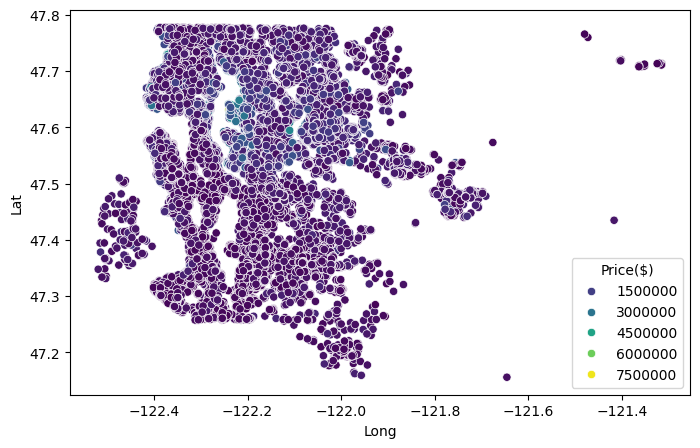

In [24]:
#Display of the geographic locations of the houses
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Long', y='Lat', hue='Price($)', data=data, palette='viridis') 
plt.show()

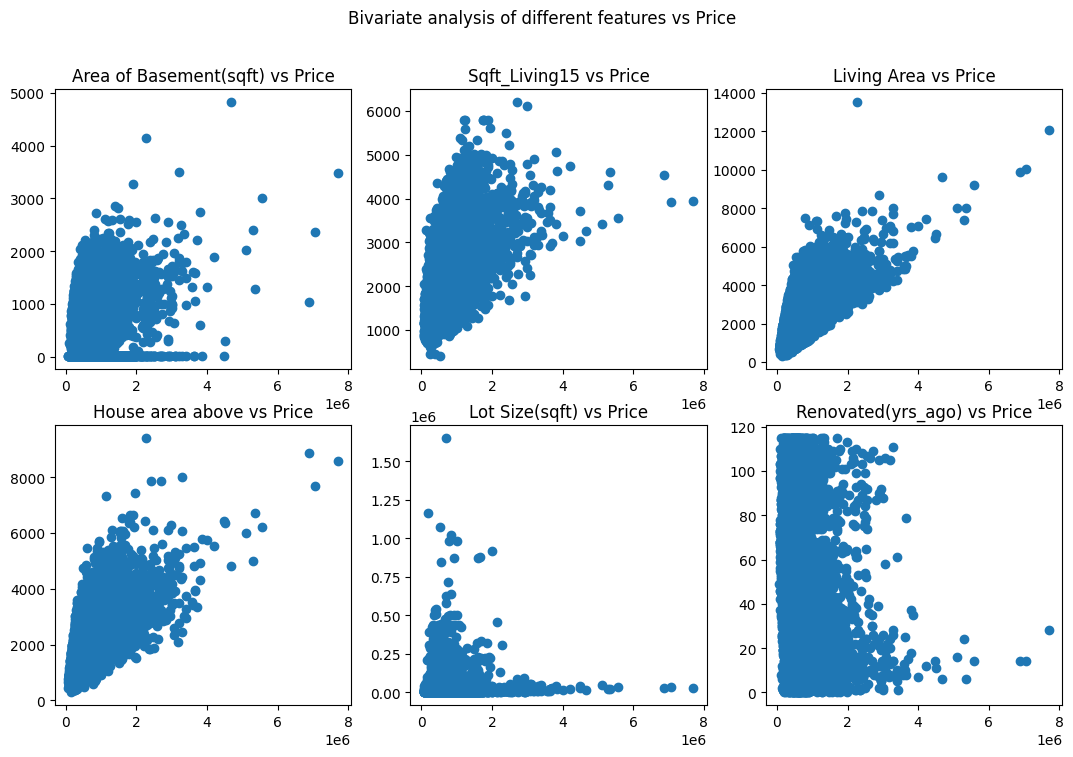

In [25]:
# Bivariate analysis of different variables and target variable

fig, axs = plt.subplots(2, 3, figsize=(13, 8))
fig.suptitle("Bivariate analysis of different features vs Price")

axs[0, 0].set_title("Area of Basement(sqft) vs Price")
axs[0, 0].scatter(data['Price($)'], data['Area of Basement(sqft)'])

axs[0, 1].set_title("Sqft_Living15 vs Price")
axs[0, 1].scatter(data['Price($)'], data['Sqft_Living15'])

axs[0, 2].set_title("Living Area vs Price")
axs[0, 2].scatter(data['Price($)'], data['Living Area(sqft)'])

axs[1, 0].set_title("House area above vs Price")
axs[1, 0].scatter(data['Price($)'], data['House Area Above(sqft)'])

axs[1, 1].set_title("Lot Size(sqft) vs Price")
axs[1, 1].scatter(data['Price($)'], data['Lot Size(sqft)'])

axs[1, 2].set_title("Renovated(yrs_ago) vs Price")
axs[1, 2].scatter(data['Price($)'], data['Renovated(yrs_ago)'])

plt.savefig("bivariate.png")

plt.show()

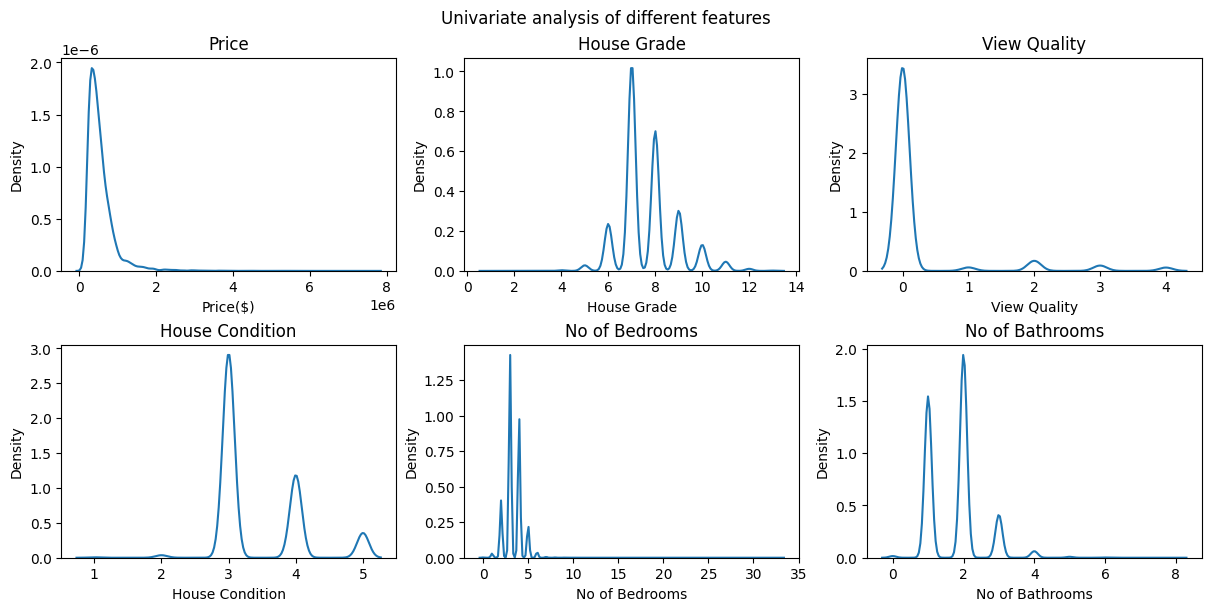

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)
fig.suptitle("Univariate analysis of different features")

# First row
axs[0, 0].set_title("Price")
sns.kdeplot(data=data, x='Price($)', ax=axs[0, 0])

axs[0, 1].set_title("House Grade")
sns.kdeplot(data=data, x='House Grade', ax=axs[0, 1])

axs[0, 2].set_title("View Quality")
sns.kdeplot(data=data, x='View Quality', ax=axs[0, 2])

# Second row
axs[1, 0].set_title("House Condition")
sns.kdeplot(data=data, x='House Condition', ax=axs[1, 0])

axs[1, 1].set_title("No of Bedrooms")
sns.kdeplot(data=data, x='No of Bedrooms', ax=axs[1, 1])

axs[1, 2].set_title("No of Bathrooms")
sns.kdeplot(data=data, x='No of Bathrooms', ax=axs[1, 2])

plt.savefig("univariate.png")

plt.show()


#### **DATA PREPROCESSING**

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

In [28]:
X = data.drop("Price($)", axis = 1)
y = data["Price($)"]

In [29]:
#Split the data into Test and Train data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 23)

In [30]:
#Print out the shape of the train and test data
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(16209, 17) (16209,)
(5404, 17) (5404,)


In [31]:
#Select the columns to scale from the X_train and X_test data
X_train_features_to_scale = X_train.drop(["View Quality", "Waterfront", "House Condition", "House Grade"], axis = 1)
X_test_features_to_scale = X_test.drop(["View Quality", "Waterfront", "House Condition", "House Grade"], axis = 1)

In [32]:
#Select the ordinal features on the dataset
X_train_ordinal_features = X_train[["View Quality", "Waterfront", "House Condition", "House Grade"]]
X_test_ordinal_features = X_test[["View Quality", "Waterfront", "House Condition", "House Grade"]]

In [33]:
#Initialize the Standard Scaler object
std_scaler = StandardScaler()

In [34]:
X_train_trans = pd.DataFrame(std_scaler.fit_transform(X_train_features_to_scale),
                                 columns = std_scaler.get_feature_names_out(), 
                                    index = X_train_features_to_scale.index)

In [35]:
X_test_trans = pd.DataFrame(std_scaler.transform(X_test_features_to_scale),
                                 columns = std_scaler.get_feature_names_out(), 
                                    index = X_test_features_to_scale.index)

In [36]:
#Concat the scaled features and the ordinal features of the X_train and X_test data
X_train = pd.concat([X_train_trans, X_train_ordinal_features], axis = 1)
X_test = pd.concat([X_test_trans, X_test_ordinal_features], axis = 1)

In [37]:
print(X_train.columns.to_list())

['Year Sold', 'No of Bedrooms', 'No of Bathrooms', 'Living Area(sqft)', 'Lot Size(sqft)', 'No of Floors', 'House Area Above(sqft)', 'Area of Basement(sqft)', 'Lat', 'Long', 'Sqft_Living15', 'Sqft_Lot15', 'Renovated(yrs_ago)', 'View Quality', 'Waterfront', 'House Condition', 'House Grade']


In [38]:
X_train.describe().round(2)

,Year Sold,No of Bedrooms,No of Bathrooms,Living Area(sqft),Lot Size(sqft),No of Floors,House Area Above(sqft),Area of Basement(sqft),Lat,Long,Sqft_Living15,Sqft_Lot15,Renovated(yrs_ago),View Quality,Waterfront,House Condition,House Grade
count,16209.00,16209.00,16209.00,16209.00,16209.00,16209.00,16209.00,16209.00,16209.00,16209.00,16209.00,16209.00,16209.00,16209.00,16209.00,16209.00,16209.00
mean,0.00,0.00,0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.24,0.01,3.41,7.65
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.77,0.09,0.65,1.17
min,-0.69,-3.60,-2.37,-1.85,-0.35,-0.80,-1.70,-0.66,-2.92,-2.16,-2.31,-0.44,-1.45,0.00,0.00,1.00,3.00
25%,-0.69,-0.40,-1.01,-0.70,-0.24,-0.80,-0.72,-0.66,-0.64,-0.81,-0.73,-0.28,-0.90,0.00,0.00,3.00,7.00
50%,-0.69,-0.40,0.34,-0.19,-0.18,-0.80,-0.27,-0.66,0.08,-0.13,-0.22,-0.19,-0.13,0.00,0.00,3.00,7.00
75%,1.44,0.67,0.34,0.50,-0.11,1.01,0.49,0.60,0.85,0.62,0.54,-0.10,0.67,0.00,0.00,4.00,8.00
max,1.44,31.65,8.46,12.41,38.46,2.83,9.20,10.23,1.57,6.37,6.17,31.21,2.54,4.00,1.00,5.00,13.00


In [39]:
X_test.describe().round(2)

,Year Sold,No of Bedrooms,No of Bathrooms,Living Area(sqft),Lot Size(sqft),No of Floors,House Area Above(sqft),Area of Basement(sqft),Lat,Long,Sqft_Living15,Sqft_Lot15,Renovated(yrs_ago),View Quality,Waterfront,House Condition,House Grade
count,5404.00,5404.00,5404.00,5404.00,5404.00,5404.00,5404.00,5404.00,5404.00,5404.00,5404.00,5404.00,5404.00,5404.00,5404.00,5404.00,5404.00
mean,-0.02,-0.00,-0.00,0.02,-0.01,0.03,0.02,-0.01,0.00,0.01,0.03,-0.00,-0.02,0.22,0.01,3.40,7.67
std,0.99,0.97,0.98,0.98,0.89,1.01,0.99,1.00,1.00,0.99,1.00,0.97,1.00,0.74,0.08,0.65,1.19
min,-0.69,-3.60,-2.37,-1.93,-0.34,-0.80,-1.80,-0.66,-2.85,-2.10,-1.99,-0.44,-1.45,0.00,0.00,1.00,1.00
25%,-0.69,-0.40,-1.01,-0.70,-0.24,-0.80,-0.70,-0.66,-0.64,-0.80,-0.71,-0.28,-0.90,0.00,0.00,3.00,7.00
50%,-0.69,-0.40,0.34,-0.15,-0.18,-0.80,-0.27,-0.66,0.09,-0.09,-0.18,-0.19,-0.17,0.00,0.00,3.00,7.00
75%,1.44,0.67,0.34,0.53,-0.11,1.01,0.57,0.58,0.85,0.65,0.60,-0.10,0.67,0.00,0.00,4.00,8.00
max,1.44,7.08,5.75,7.14,21.28,2.83,6.68,7.25,1.57,5.74,5.56,14.51,2.54,4.00,1.00,5.00,13.00


#### **MODEL TRAINING USING LINEAR REGRESSION**

In [40]:
%%time
LR = LinearRegression()
LR.fit(X_train, y_train)
pred = LR.predict(X_test)
print("Model's Error:", mean_absolute_error(y_test, pred))

Model's Error: 126746.63395122185
CPU times: total: 78.1 ms
Wall time: 101 ms


In [41]:
output_df = pd.DataFrame({'Actual': y_test})
output_df['Linear Regression Predictions'] = pred

output_df.head()

,Actual,Linear Regression Predictions
12626,209900.0,39901.136027
8629,575000.0,674703.172923
2992,320000.0,447845.799480
17161,560000.0,732355.021990
14238,240000.0,368631.647007


###### Visualize the predicted prices vs the actual prices

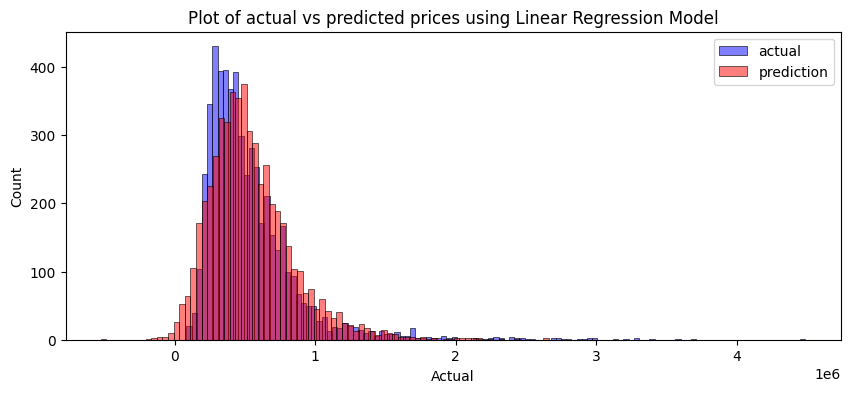

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, ax = plt.subplots(figsize=(10,4))

sns.histplot(output_df['Actual'], color='blue', alpha=0.5, label="actual")
sns.histplot(output_df['Linear Regression Predictions'], color='red', alpha=0.5, label="prediction")
plt.title("Plot of actual vs predicted prices using Linear Regression Model")

plt.legend()
plt.savefig("Linear regression.png")
plt.show()

#### **MODEL TRAINING USING DECISON TREE MODEL REGRESSOR**

In [43]:
from sklearn.tree import DecisionTreeRegressor

In [44]:
%%time
dt = DecisionTreeRegressor(max_depth=5, random_state=0)
dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)
print("Model's Error:", mean_absolute_error(y_test, y_pred))

Model's Error: 112537.34414521254
CPU times: total: 281 ms
Wall time: 345 ms


In [45]:
output_df = pd.DataFrame({'Actual': y_test})
output_df['Decision Tree Regresor Predictions'] = y_pred

output_df.head()

,Actual,Decision Tree Regresor Predictions
12626,209900.0,241767.787597
8629,575000.0,523939.262840
2992,320000.0,436934.111607
17161,560000.0,888262.498148
14238,240000.0,345567.978233


###### Visualize the predicted prices vs the actual prices

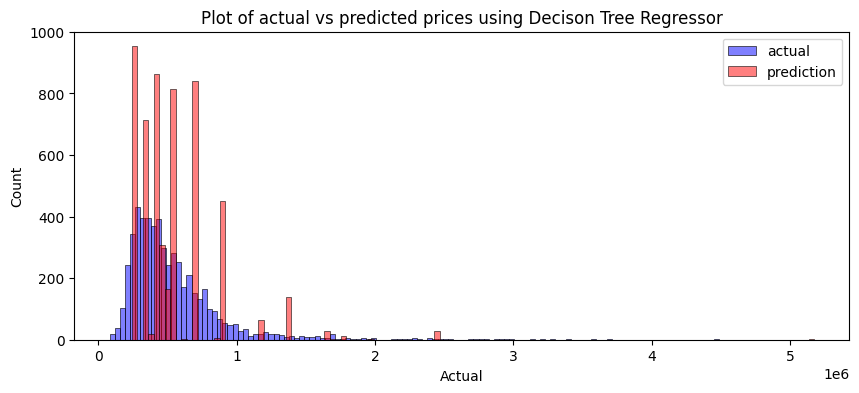

In [46]:
fig, ax = plt.subplots(figsize=(10,4))

sns.histplot(output_df['Actual'], color='blue', alpha=0.5, label="actual")
sns.histplot(output_df['Decision Tree Regresor Predictions'], color='red', alpha=0.5, label="prediction")
plt.title("Plot of actual vs predicted prices using Decison Tree Regressor")

plt.legend()
plt.savefig("Decision Tree mode.png")
plt.show()

#### `From the visualization above, you can see that the DT model did'nt do so well compared to the first`

#### **MODEL TRAINING USING RANDOM FOREST REGRESSOR**

In [47]:
from sklearn.ensemble import RandomForestRegressor

In [48]:
%%time
rf = RandomForestRegressor(n_estimators=100, max_depth=None, random_state=0)
rf.fit(X_train, y_train)
y_pred1 = rf.predict(X_test)
print("Model's Error:", mean_absolute_error(y_test, y_pred1))

Model's Error: 67789.55816239734
CPU times: total: 55.9 s
Wall time: 1min 14s


In [49]:
output_df = pd.DataFrame({'Actual': y_test})

In [50]:
output_df['Random Forest Regressor Predictions'] = y_pred1

output_df.head()

,Actual,Random Forest Regressor Predictions
12626,209900.0,224090.000000
8629,575000.0,634753.030000
2992,320000.0,424421.630000
17161,560000.0,664551.050000
14238,240000.0,282342.456667


###### Visualize the predicted prices vs the actual prices

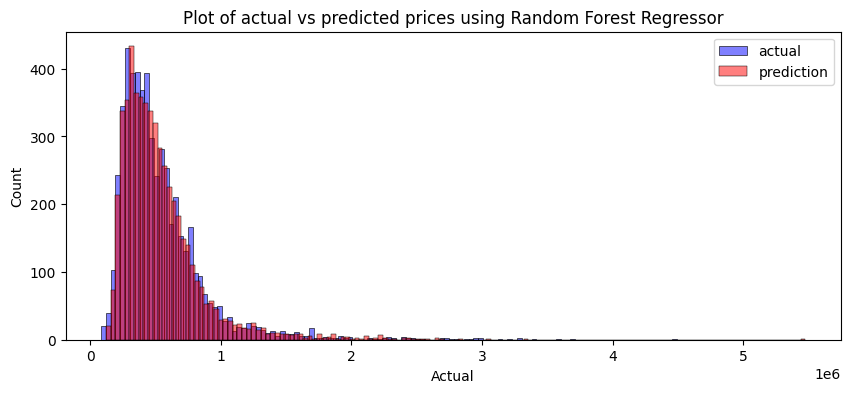

In [51]:
fig, ax = plt.subplots(figsize=(10,4))

sns.histplot(output_df['Actual'], color='blue', alpha=0.5, label="actual")
sns.histplot(output_df['Random Forest Regressor Predictions'], color='red', alpha=0.5, label="prediction")
plt.title("Plot of actual vs predicted prices using Random Forest Regressor")

plt.legend()
plt.savefig("Random Forest.png")
plt.show()

#### `From the visualization and the error estimation, this model did better than the first two`

#### **MODEL TRAINING WITH KNN REGRESSOR**

In [52]:
from sklearn.neighbors import KNeighborsRegressor

In [53]:
%%time
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred5 = knn.predict(X_test)
print("Model's Error:", mean_absolute_error(y_test, y_pred5))

Model's Error: 93124.57039230199
CPU times: total: 2.69 s
Wall time: 2.06 s


In [54]:
output_df = pd.DataFrame({'Actual': y_test})

In [55]:
output_df['KNN Regressor Predictions'] = y_pred5

output_df.head()

,Actual,KNN Regressor Predictions
12626,209900.0,275800.0
8629,575000.0,638650.0
2992,320000.0,356090.0
17161,560000.0,584730.0
14238,240000.0,356300.0


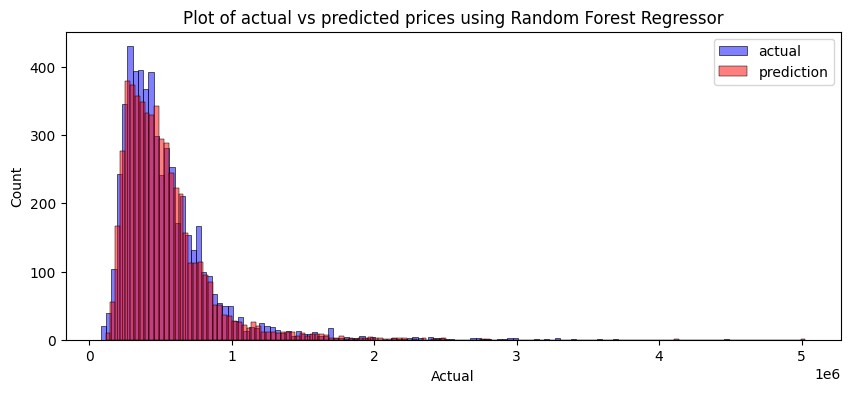

In [56]:
fig, ax = plt.subplots(figsize=(10,4))

sns.histplot(output_df['Actual'], color='blue', alpha=0.5, label="actual")
sns.histplot(output_df['KNN Regressor Predictions'], color='red', alpha=0.5, label="prediction")
plt.title("Plot of actual vs predicted prices using Random Forest Regressor")

plt.legend()
plt.savefig("Knn.png")
plt.show()

#### **MODEL TRAINING USING LINEAR REGRESSION MODEL WITH SELECTED FEATURES**

In [57]:
#Run through the correlation of the features
data.corr()

,Year Sold,No of Bedrooms,No of Bathrooms,Living Area(sqft),Lot Size(sqft),No of Floors,Waterfront,View Quality,House Condition,House Grade,House Area Above(sqft),Area of Basement(sqft),Lat,Long,Sqft_Living15,Sqft_Lot15,Price($),Renovated(yrs_ago)
Year Sold,1.000000,-0.009838,-0.021698,-0.029038,0.005468,-0.019465,-0.004165,0.001364,-0.045589,-0.030387,-0.023836,-0.015687,-0.029212,0.000270,-0.021734,-0.000085,0.003576,0.006404
No of Bedrooms,-0.009838,1.000000,0.467452,0.576671,0.031703,0.155643,-0.006582,0.079532,0.028472,0.356967,0.477610,0.303093,-0.008931,0.129473,0.391638,0.029244,0.308350,-0.165506
No of Bathrooms,-0.021698,0.467452,1.000000,0.697875,0.085310,0.484822,0.058798,0.177257,-0.126016,0.606631,0.639922,0.250880,0.031351,0.179351,0.510049,0.080779,0.510072,-0.467845
Living Area(sqft),-0.029038,0.576671,0.697875,1.000000,0.172826,0.353321,0.103818,0.284611,-0.058753,0.762704,0.876586,0.435043,0.052529,0.240223,0.756420,0.183286,0.702035,-0.343745
Lot Size(sqft),0.005468,0.031703,0.085310,0.172826,1.000000,-0.008951,0.021604,0.074710,-0.008958,0.113621,0.183510,0.015286,-0.085683,0.229521,0.144608,0.718557,0.089661,-0.052911
No of Floors,-0.019465,0.155643,0.484822,0.353321,-0.008951,1.000000,0.019640,0.024658,-0.293173,0.472608,0.517908,-0.235836,0.029567,0.159001,0.296561,-0.013252,0.237211,-0.587772
Waterfront,-0.004165,-0.006582,0.058798,0.103818,0.021604,0.019640,1.000000,0.401857,0.016653,0.082775,0.072074,0.080588,-0.014274,-0.041910,0.086463,0.030703,0.266369,0.000537
View Quality,0.001364,0.079532,0.177257,0.284611,0.074710,0.024658,0.401857,1.000000,0.045990,0.251321,0.167648,0.276947,0.006157,-0.078400,0.280439,0.072575,0.397293,0.018264
House Condition,-0.045589,0.028472,-0.126016,-0.058753,-0.008958,-0.293173,0.016653,0.045990,1.000000,-0.144674,-0.158202,0.174105,-0.014941,-0.106500,-0.092824,-0.003406,0.036362,0.396358
House Grade,-0.030387,0.356967,0.606631,0.762704,0.113621,0.472608,0.082775,0.251321,-0.144674,1.000000,0.755917,0.168392,0.114084,0.198372,0.713202,0.119248,0.667434,-0.460796


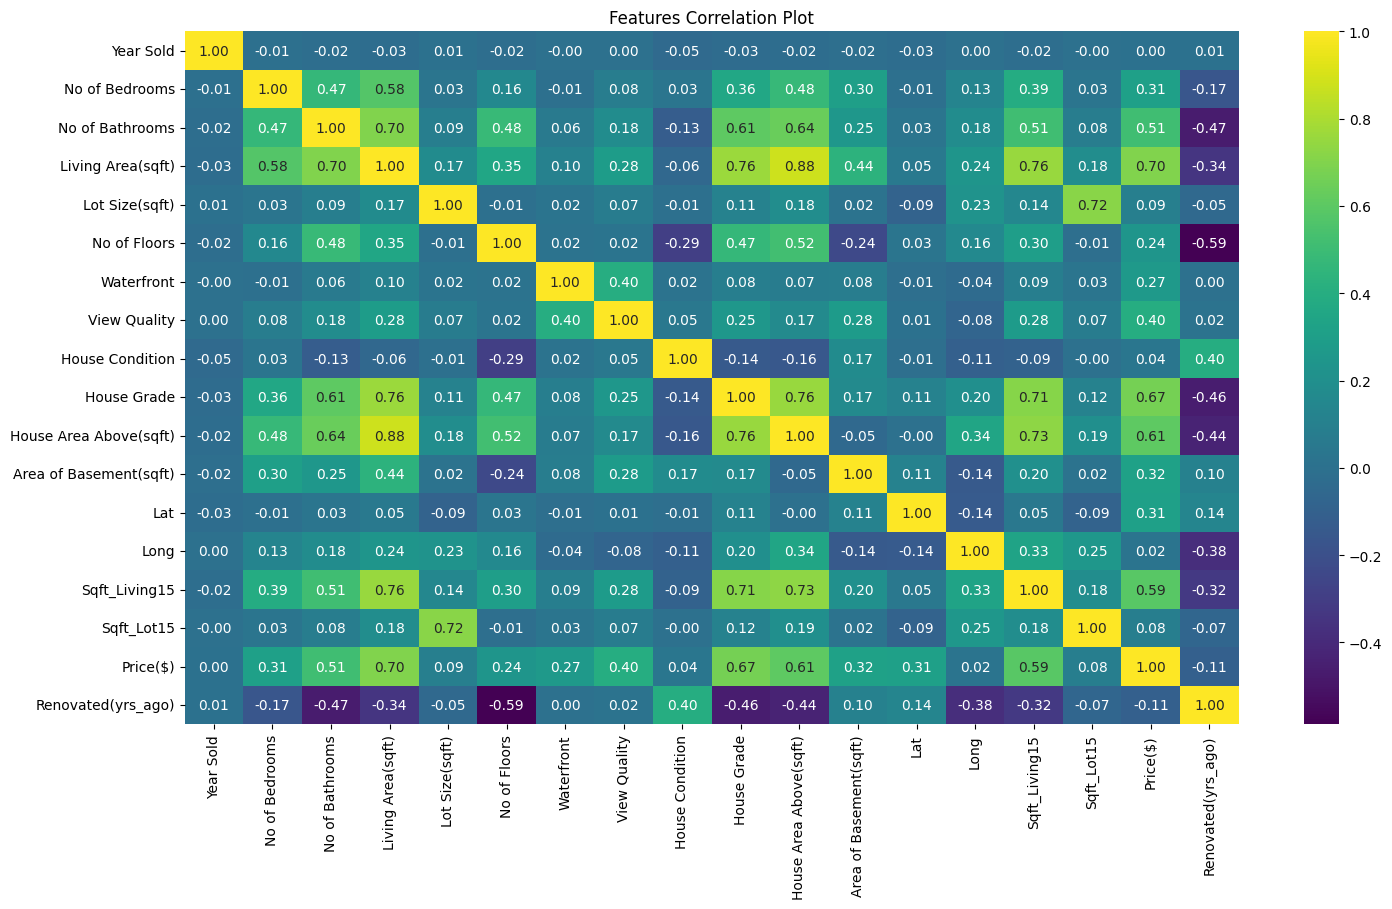

In [58]:
plt.figure(figsize = (17, 9))
sns.heatmap(data.corr(),annot=True,
            fmt=".2f",
            cmap="viridis")
plt.title("Features Correlation Plot")
plt.show();

In [59]:
#Now drop columns tha have no correlation with the price column
X_train = X_train.drop(['Year Sold', 'Lot Size(sqft)', 'House Condition', 'Long', 'Sqft_Lot15'], axis=1)
X_test = X_test.drop(['Year Sold', 'Lot Size(sqft)', 'House Condition', 'Long', 'Sqft_Lot15'], axis=1)

In [60]:
%%time
LR2 = LinearRegression()
LR2.fit(X_train, y_train)
y_pred2 = LR2.predict(X_test)
print("Model's Error:", mean_absolute_error(y_test, y_pred2))

Model's Error: 127994.40160684273
CPU times: total: 250 ms
Wall time: 120 ms


In [61]:
output_df = pd.DataFrame({'Actual': y_test})

In [62]:
output_df['Linear Regression Predictions 2'] = y_pred2

output_df.head()

,Actual,Linear Regression Predictions 2
12626,209900.0,48372.879492
8629,575000.0,658159.324162
2992,320000.0,433185.324355
17161,560000.0,737487.431795
14238,240000.0,322848.962234


###### Visualize the predicted prices vs the actual prices

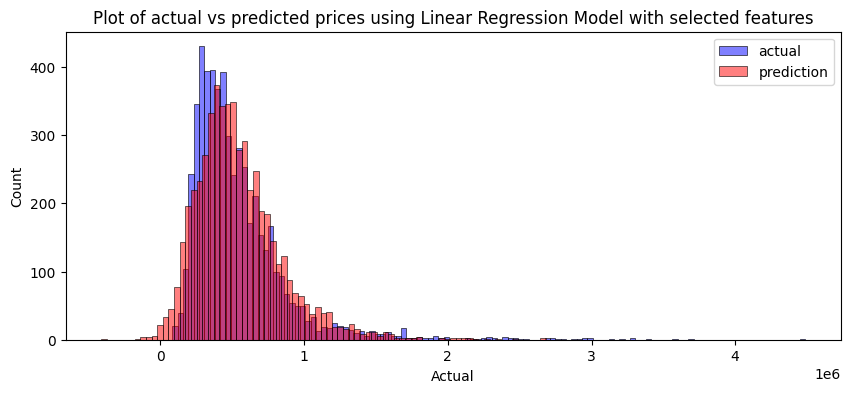

In [63]:
fig, ax = plt.subplots(figsize=(10,4))

sns.histplot(output_df['Actual'], color='blue', alpha=0.5, label="actual")
sns.histplot(output_df['Linear Regression Predictions 2'], color='red', alpha=0.5, label="prediction")
plt.title("Plot of actual vs predicted prices using Linear Regression Model with selected features")

plt.legend()
plt.savefig("Linear Regression2.png")
plt.show()

**Now use the same feature selection for the Random Forest model since it worked better for the 1st set of features**

In [64]:
%%time
rf2 = RandomForestRegressor(n_estimators=100, max_depth=None, random_state=0)
rf2.fit(X_train, y_train)
y_pred3 = rf2.predict(X_test)
print("Model's Error:", mean_absolute_error(y_test, y_pred3))

Model's Error: 82505.07327688484
CPU times: total: 41.3 s
Wall time: 48.6 s


In [65]:
output_df = pd.DataFrame({'Actual': y_test})

In [66]:
output_df['Random Forest Regressor 2'] = y_pred3

output_df.head()

,Actual,Random Forest Regressor 2
12626,209900.0,221943.90
8629,575000.0,662589.03
2992,320000.0,422968.00
17161,560000.0,654138.00
14238,240000.0,276467.40


###### Visualize the predicted prices vs the actual prices

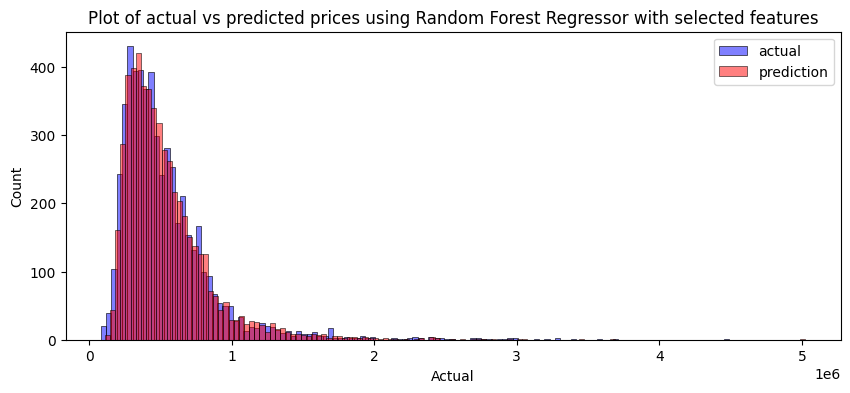

In [67]:
fig, ax = plt.subplots(figsize=(10,4))

sns.histplot(output_df['Actual'], color='blue', alpha=0.5, label="actual")
sns.histplot(output_df['Random Forest Regressor 2'], color='red', alpha=0.5, label="prediction")
plt.title("Plot of actual vs predicted prices using Random Forest Regressor with selected features")

plt.legend()
plt.savefig("Random Forest.png")
plt.show()

**Now print out the metrics of all five trained models and select the best**

In [68]:
print("The mean absolute error of the 1st Linear regression model is:", mean_absolute_error(y_test, pred).round(2),)
print("The mean absolute error of the decision tree regressor is:", mean_absolute_error(y_test, y_pred).round(2),)
print("The mean absolute error of the 1st random forest regressor is:", mean_absolute_error(y_test, y_pred1).round(2),)
print("The mean absolute error of the knn regressor is:", mean_absolute_error(y_test, y_pred5).round(2),)
print("The mean absolute error of the 2nd Linear regression model is:", mean_absolute_error(y_test, y_pred2).round(2),)
print("The mean absolute error of the 2nd random forest regressor is:", mean_absolute_error(y_test, y_pred3).round(2),)

The mean absolute error of the 1st Linear regression model is: 126746.63
The mean absolute error of the decision tree regressor is: 112537.34
The mean absolute error of the 1st random forest regressor is: 67789.56
The mean absolute error of the knn regressor is: 93124.57
The mean absolute error of the 2nd Linear regression model is: 127994.4
The mean absolute error of the 2nd random forest regressor is: 82505.07


##### **From the above, the 1st random forest model works best for the House price prediction. This was resolved from the different model visualizations and the error estimations. So I will go with it**
* This can backed by the fact that the random forest model handles non-linear relationships and interactions between features better than linear regression, which assumes a linear relationship. 

In [69]:
import joblib

In [70]:
#Now dump the model
joblib.dump(rf, "House_price_predictor.pkl")

['House_price_predictor.pkl']

In [71]:
joblib.dump(std_scaler, "features_standard_scaling.pkl")

['features_standard_scaling.pkl']